<a href="https://colab.research.google.com/github/Dalton115/MAT-422/blob/main/HW3_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW3.4

   * Used Gemini as a study aid and coding partner to clarify multivariate calculus definitions, debug python code, and format LaTex formulas.

_________________
# Logistic Regression (3.4):

Key Concepts (summarized and demonstrated with python):

* Binary Classification: We are given dataset pairs $(\alpha_i, b_i)$ for $i = 1, \dots, n$, where features $\alpha_i \in \mathbb{R}^d$ and binary labels $b_i \in \{0, 1\}$.

* The Logit Link: Logistic regression models the log-odds (logit) of the probability $p(\alpha; x)$ that a label equals $1$ as a linear function of the features:$$\log \frac{p(\alpha; x)}{1 - p(\alpha; x)} = \alpha^T x$$

* The Sigmoid Function: Rearranging the logit equation gives the probability prediction via the standard logistic (sigmoid) function $\sigma(t)$:$$p(\alpha; x) = \sigma(\alpha^T x) where \quad \sigma(t) = \frac{1}{1 + e^{-t}}$$

* ConvexityCross-Entropy Loss: To find the optimal parameter vector $x$, we maximize the likelihood, which is equivalent to minimizing the average cross-entropy loss:$$\ell(x; A, b) = -\frac{1}{n} \sum_{i=1}^n \left[ b_i \log(\sigma(\alpha_i^T x)) + (1 - b_i) \log(1 - \sigma(\alpha_i^T x)) \right]$$

* Gradient: Using the chain rule and the property $\sigma'(t) = \sigma(t)(1 - \sigma(t))$, the gradient of the loss with respect to $x$ is:$$\nabla_x \ell(x; A, b) = -\frac{1}{n} \sum_{i=1}^n (b_i - \sigma(\alpha_i^T x))\alpha_i$$

* Hessian & Convexity: The Hessian matrix is given by:$$\nabla^2_x \ell(x; A, b) = \frac{1}{n} \sum_{i=1}^n \sigma(\alpha_i^T x)(1 - \sigma(\alpha_i^T x)) \alpha_i \alpha_i^T$$Since each outer product $\alpha_i \alpha_i^T$ is symmetric and positive semi-definite (PSD), the cross-entropy loss is a convex function, guaranteeing that gradient descent will find the global minimum.

* Gradient Descent: Updates parameters iteratively using the full batch:$$x_{k+1} = x_k + \beta \frac{1}{n} \sum_{i=1}^n (b_i - \sigma(\alpha_i^T x_k)) \alpha_i$$

* Stochastic Gradient Descent (SGD): Instead of the full batch, updates using a single randomly chosen sample index $I$:$$x_{k+1} = x_k + \beta (b_I - \sigma(\alpha_I^T x_k)) \alpha_I$$




Feature matrix A shape: (200, 2)
Labels vector b shape: (200,)
Optimized weights (x): [1.78826125 2.0638163 ]
Final Cross-Entropy Loss: 0.009127734951807123
Model Success Rate (Accuracy): 99.50%


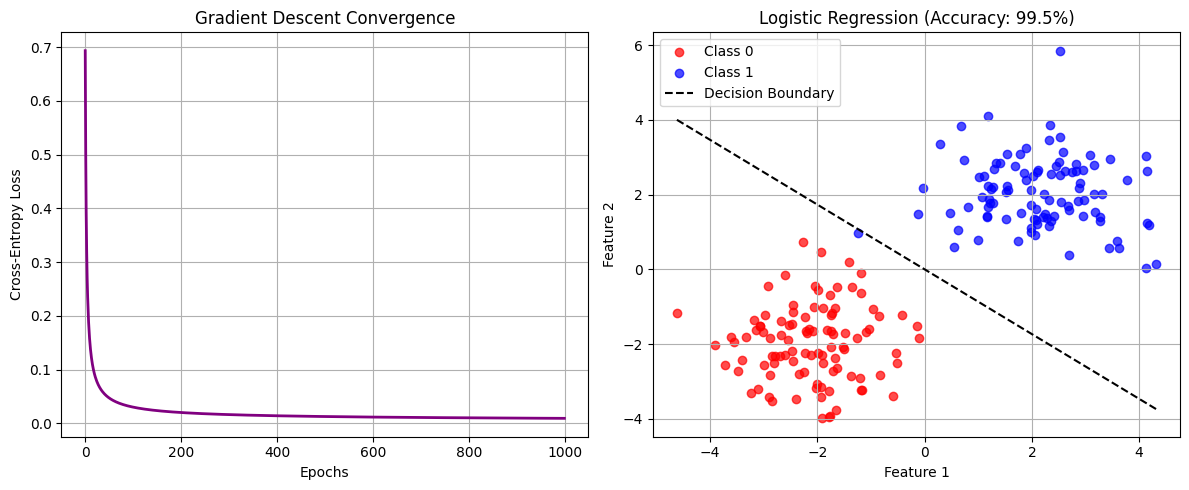

--- TRUE MANUAL (SCALAR) VERIFICATION ---
Pure Manual Loop Gradient: [-0.00247112 -0.00582722]
NumPy Vectorized Gradient: [-0.00247112 -0.00582722]

Verification Passed: Pure scalar manual loop matches NumPy vectorization perfectly!


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Set random seed for reproducibility
np.random.seed(42)

# Generate synthetic data for binary classification (d = 2 features, n = 200 samples)
n = 200
d = 2

class_0_features = np.random.randn(n // 2, d) + np.array([-2, -2])
class_1_features = np.random.randn(n // 2, d) + np.array([2, 2])

A = np.vstack((class_0_features, class_1_features))
b = np.array([0] * (n // 2) + [1] * (n // 2))

print(f"Feature matrix A shape: {A.shape}")
print(f"Labels vector b shape: {b.shape}")

def sigmoid(t):
    """Compute the logistic sigmoid function safely."""
    t = np.clip(t, -500, 500)
    return 1.0 / (1.0 + np.exp(-t))

def cross_entropy_loss(x, A, b):
    """Compute the average cross-entropy loss."""
    n = len(b)
    p = sigmoid(np.dot(A, x))
    eps = 1e-15
    p = np.clip(p, eps, 1 - eps)
    loss = -np.mean(b * np.log(p) + (1 - b) * np.log(1 - p))
    return loss

def compute_gradient(x, A, b):
    """Compute the gradient of the cross-entropy loss with respect to x using NumPy."""
    n = len(b)
    p = sigmoid(np.dot(A, x))
    grad = -np.dot(A.T, (b - p)) / n
    return grad

    # Initialize parameters x to zeros
x = np.zeros(d)
beta = 0.1  # Learning rate
epochs = 1000

loss_history = []

for epoch in range(epochs):
    current_loss = cross_entropy_loss(x, A, b)
    loss_history.append(current_loss)

    # Gradient step update using our gradient function
    grad = compute_gradient(x, A, b)
    x -= beta * grad  # Gradient descent moves opposite to the gradient

print("Optimized weights (x):", x)
print("Final Cross-Entropy Loss:", loss_history[-1])

# --- SUCCESS RATE (ACCURACY) EVALUATION ---
probabilities = sigmoid(np.dot(A, x))
predictions = (probabilities >= 0.5).astype(int)
success_rate = np.mean(predictions == b) * 100
print(f"Model Success Rate (Accuracy): {success_rate:.2f}%")

plt.figure(figsize=(12, 5))

# Plot 1: Loss History
plt.subplot(1, 2, 1)
plt.plot(loss_history, color='purple', lw=2)
plt.title("Gradient Descent Convergence")
plt.xlabel("Epochs")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)

# Plot 2: Decision Boundary & Data Points
plt.subplot(1, 2, 2)
plt.scatter(A[b == 0, 0], A[b == 0, 1], color='red', label='Class 0', alpha=0.7)
plt.scatter(A[b == 1, 0], A[b == 1, 1], color='blue', label='Class 1', alpha=0.7)

x_vals = np.linspace(np.min(A[:, 0]), np.max(A[:, 0]), 100)
if x[1] != 0:
    y_vals = -(x[0] / x[1]) * x_vals
    plt.plot(x_vals, y_vals, color='black', linestyle='--', label='Decision Boundary')

plt.title(f"Logistic Regression (Accuracy: {success_rate:.1f}%)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("--- TRUE MANUAL (SCALAR) VERIFICATION ---")

num_samples = len(b)
dim = len(x)

# Compute the gradient purely through scalar loops and basic math (no vectorized np.dot)
manual_grad = np.zeros(dim)

for i in range(num_samples):
    alpha_i = A[i]
    b_i = b[i]

    # 1. Scalar linear combination: alpha_i^T * x
    linear_comb = sum(alpha_i[j] * x[j] for j in range(dim))

    # 2. Scalar sigmoid using pure Python math.exp
    clipped_lc = max(min(linear_comb, 500.0), -500.0)
    p_i = 1.0 / (1.0 + math.exp(-clipped_lc))

    # 3. Accumulate component-wise terms for the sum: (b_i - p_i) * alpha_i
    for j in range(dim):
        manual_grad[j] += (b_i - p_i) * alpha_i[j]

# Apply the negative average factor to match the loss gradient definition: -(1/n) * sum(...)
manual_grad = -manual_grad / num_samples

# Retrieve the NumPy vectorized function gradient
numpy_grad = compute_gradient(x, A, b)

print(f"Pure Manual Loop Gradient: {manual_grad}")
print(f"NumPy Vectorized Gradient: {numpy_grad}")

# Assert that both methods yield identical results
assert np.allclose(manual_grad, numpy_grad, atol=1e-12), "Mismatch between manual loop and NumPy!"
print("\nVerification Passed: Pure scalar manual loop matches NumPy vectorization perfectly!")

The above section of code demonstrates the gradient descent convergence, and visualizes its accuracy at separating two classes. It was successful at separating the two classes.

Additionally we double checked the NumPy vectorization with a manual loop to see if they line up, which they did.

# Checklist


*   Read, checked, and personalized each example. Also extended at least one example. They run without errors.
*   Covered key concepts from the textbook and illustrated them in python.
*   Explanations written in my own words accompany each example.
*   Saved directly from collab to github.
*   Carefully formatted, code is explained in comments, and it follows the given order from the textbook and in the canvas assignment